# A machine learning approach to volatility forecasting: replication and extension to 2015–2026

**Paper:** Christensen, Siggaard & Veliyev (2022/2023), *A machine learning approach to volatility forecasting*, Journal of Financial Econometrics (arXiv:2601.13014).

**Research question.** The paper shows (DJIA stocks, 2001–2017) that off-the-shelf ML (regularization, random forest, neural nets) beats the HAR model family in forecasting realized variance, and that the edge grows with the information set and the forecast horizon. **Does this result hold out-of-sample in a new, non-overlapping market regime (2015–2026), using only open data?**

**Data.** 5-minute realized measures for the Dow 30 from **VOLARE** (Cipollini et al., 2026, arXiv:2602.19732, https://volare.unime.it), open-access and built from cleaned tick data, plus public macro series (FRED, Philadelphia Fed, Yahoo Finance).

**Design (as in the paper).** 70/10/20 train/validation/test split; HAR, HAR-X, LogHAR, LevHAR, SHAR, HARQ vs. ridge, lasso, elastic net, random forest, gradient boosting, neural nets; information sets $\mathcal M_{HAR}$ (RV lags only) and $\mathcal M_{ALL}$ (+ extra predictors); horizons 1, 5, 22 days; relative MSE + Diebold–Mariano tests; ALE-based variable importance.

All code lives in `volml.py`; this notebook runs it and produces every table and figure.

In [1]:
# !pip install pandas numpy scipy scikit-learn matplotlib joblib openpyxl yfinance pyarrow
import os, time
import numpy as np, pandas as pd, matplotlib.pyplot as plt
import volml as V

QUICK = True        # True: 8 stocks + lighter models for a first pass (~10-20 min). False: full run.
DRY_RUN = False     # True: simulated data, no downloads needed (pipeline test only)

# Data source: "volare" (preferred) | "alpaca" (5-min bars, 2016+) | "yahoo" (daily range proxy, 2001+) | "binance" (crypto)
# Fallback files are created with:  python fetch_data.py alpaca|yahoo|binance  (see README)
DATA_SOURCE = "alpaca"
PATHS = {"volare": "data/volare", "alpaca": "data/alpaca/realized.csv",
         "yahoo": "data/yahoo/realized.csv", "binance": "data/binance/realized.csv"}
cfg = V.Config(volare_path=PATHS[DATA_SOURCE])
if DATA_SOURCE == "yahoo":
    cfg.start = "2001-01-01"      # paper window + extension; set cfg.end = "2017-12-31" to mimic the paper sample
# per-stock implied vol from LSEG (python fetch_iv_lseg.py) is used automatically if present
cfg.iv_file = "data/lseg/iv.csv" if os.path.exists("data/lseg/iv.csv") else None
if QUICK and DATA_SOURCE != "binance":
    cfg.symbols = ["AAPL", "MSFT", "JPM", "KO", "BA", "CVX", "WMT", "IBM"]
    cfg.rf_trees, cfg.nn_seeds, cfg.nn_top, cfg.refit_trees = 200, 5, 3, 126
os.makedirs(cfg.results_dir, exist_ok=True)
cfg

Config(volare_path='data/alpaca/realized.csv', symbols=['AAPL', 'MSFT', 'JPM', 'KO', 'BA', 'CVX', 'WMT', 'IBM'], start='2015-01-01', end=None, horizons=(1, 5, 22), datasets=('M_HAR', 'M_ALL'), train_frac=0.7, val_frac=0.1, refit_linear=1, refit_reg=22, refit_trees=126, models=('HAR', 'HAR-X', 'LogHAR', 'LevHAR', 'SHAR', 'HARQ', 'RR', 'LA', 'EN', 'RF', 'GB', 'NN'), rf_trees=200, rf_min_leaf=5, nn_archs=((4, 2),), nn_seeds=5, nn_top=3, nn_max_epochs=500, nn_patience=50, nn_lr=0.001, nn_l2=0.0001, nn_batch=32, n_jobs=-1, cache_dir='data/cache', results_dir='results', offline_macro=False, ea_file=None, iv_file='data/lseg/iv.csv', seed=42)

## 1. Data

**If VOLARE access is pending:** run `python fetch_data.py alpaca --key ... --secret ...` (free Alpaca paper account, true 5-min RV from 2016) or `python fetch_data.py yahoo` (no account, daily Garman–Klass proxy from 2001) and set `DATA_SOURCE` above accordingly. With Yahoo, HARQ and SHAR are skipped automatically (no intraday data).

**VOLARE (realized measures).** Go to https://volare.unime.it → *Download Data* → asset type *Stocks*, measure set with the 5-minute measures (`rv5`, `rq5`, `rsp5`, `rsn5`) plus open/close/volume. Put the downloaded file(s) into `data/volare/`. The loader matches column names case-insensitively and prints what it found; if a name differs, add it to `_ALIASES` in `volml.py`.

**Macro (downloaded automatically, cached in `data/cache/`).** VIX (FRED `VIXCLS`), economic policy uncertainty (FRED `USEPUINDXD`), 3-month T-bill (FRED `DTB3`, first-differenced), Hang Seng squared log return (Yahoo `^HSI`), ADS business conditions index (Philadelphia Fed).

**Firm-level extras.** Momentum (`M1W`, 5-day sum of open-to-close returns) and dollar volume (`DVOL`) are built from VOLARE. Model-free implied volatility (OptionMetrics) and earnings dates are not openly available: they can be added through `cfg.iv_file` / `cfg.ea_file` (CSV) if you get them, e.g. implied vols from LSEG Workspace.

In [2]:
if DRY_RUN:
    panel, macro = V.simulate_panel(n_stocks=6, n_days=2800)
    panel = panel.rename(columns={"rv5": "rv", "rq5": "rq", "rsp5": "rsp", "rsn5": "rsn"})
    panel[["rv", "rsp", "rsn"]] *= 1e4; panel["rq"] *= 1e8
    cfg.symbols = sorted(panel.symbol.unique())
else:
    panel = V.load_volare(cfg.volare_path, symbols=None if DATA_SOURCE == "binance" else cfg.symbols)
    if DATA_SOURCE == "binance":
        cfg.symbols = sorted(panel.symbol.unique())
    macro = V.load_macro(cfg)

ea = pd.read_csv(cfg.ea_file, parse_dates=["date"]) if cfg.ea_file else None
iv = pd.read_csv(cfg.iv_file, parse_dates=["date"]) if cfg.iv_file else None
panel.groupby("symbol")["date"].agg(["min", "max", "count"]).head(30)

VOLARE: 8 symbols, 2016-01-04 -> 2026-10-15, columns: ['date', 'symbol', 'rv', 'rq', 'rsp', 'rsn', 'open', 'close', 'volume']
macro VIX: 1990-01-02 -> 2026-10-15
macro EPU: 1985-01-01 -> 2026-10-15
macro US3M: 1954-01-04 -> 2026-10-15
macro HSI: 2014-01-03 -> 2026-10-16
macro ADS: 1960-03-01 -> 2026-10-10


,min,max,count
symbol,,,
AAPL,2016-01-04,2026-10-15,2710
BA,2016-01-04,2026-10-15,2708
CVX,2016-01-04,2026-10-15,2708
IBM,2016-01-04,2026-10-15,2709
JPM,2016-01-04,2026-10-15,2709
KO,2016-01-04,2026-10-15,2709
MSFT,2016-01-04,2026-10-15,2710
WMT,2016-01-04,2026-10-15,2708


### Descriptive statistics (cf. paper Table 1; realized volatility annualized in %)

In [3]:
ann = lambda x: np.sqrt(252 * x)     # RV is stored in (daily %)^2
desc = []
for s, g in panel.groupby("symbol"):
    f = V.build_features(g, macro, cfg, None if ea is None else ea[ea.symbol == s],
                         None if iv is None else iv[iv.symbol == s])
    t = pd.DataFrame({"RVD": ann(f["RVD"]), "RVW": ann(f["RVW"]), "RVM": ann(f["RVM"])})
    for c in V.extra_cols(f):
        t[c] = f[c]
    desc.append(t.describe().T.assign(skew=t.skew(), kurt=t.kurt() + 3))
desc = pd.concat(desc).groupby(level=0).mean()[["mean", "50%", "max", "min", "std", "skew", "kurt"]]
desc.round(2)

,mean,50%,max,min,std,skew,kurt
ADS,-0.22,-0.12,9.64,-26.64,2.77,-5.98,56.26
DVOL,0.00,-0.01,1.94,-1.21,0.32,0.49,5.04
EPU,176.26,126.85,1026.38,4.05,139.60,1.84,7.00
HSI,1.89,0.56,201.16,0.00,5.69,19.80,605.04
IV,25.18,23.48,114.73,12.03,9.10,2.35,15.77
M1W,0.12,0.20,15.05,-18.46,2.83,-0.33,7.80
RVD,19.16,16.81,148.47,5.55,10.62,4.35,37.89
RVM,20.02,18.13,89.03,9.57,8.83,3.83,26.52
RVW,19.64,17.54,122.53,7.59,9.70,4.38,36.64
US3M,-0.00,0.00,0.17,-0.22,0.02,-1.52,20.66


## 2. Forecasting (rolling out-of-sample, all models, both information sets, h = 1, 5, 22)

In [4]:
tag = f"{DATA_SOURCE}_{'quick' if QUICK else 'full'}{'_iv' if iv is not None else ''}"
cfg.results_dir = os.path.join("results", tag)            # one folder per run variant
os.makedirs(cfg.results_dir, exist_ok=True)
pkl = os.path.join(cfg.results_dir, "preds.pkl")
print("results ->", cfg.results_dir)
if os.path.exists(pkl):
    preds, info = pd.read_pickle(pkl)
else:
    t0 = time.time()
    preds, info = V.run_all(cfg, panel, macro, ea, iv)
    pd.to_pickle((preds, info), pkl)
    print(f"done in {(time.time() - t0) / 60:.1f} min")
s0 = next(iter(info))
print("sample split:", info[s0][("M_HAR", 1)]["n"])
print("tuned hyperparameters (example):", {k: v for k, v in info[s0][("M_ALL", 1)].items() if k != "n"})

results -> results\alpaca_quick_iv
train <= 2023-07-27 < val <= 2024-08-22 < test


[Parallel(n_jobs=-1)]: Using backend LokyBackend with 12 concurrent workers.
[Parallel(n_jobs=-1)]: Done   3 out of   8 | elapsed:  3.0min remaining:  4.9min
[Parallel(n_jobs=-1)]: Done   5 out of   8 | elapsed:  3.1min remaining:  1.8min


done in 3.3 min
sample split: {'train': 1881, 'val': 270, 'test': 537, 'test_start': '2024-08-23', 'test_end': '2026-10-14'}
tuned hyperparameters (example): {'RR': {'alpha': np.float64(1425.1026703029963), 'l1_ratio': None}, 'LA': {'alpha': np.float64(0.4641588833612782), 'l1_ratio': None}, 'EN': {'alpha': np.float64(0.6723357536499335), 'l1_ratio': 0.1}, 'GB': {'depth': 2, 'lr': 0.1, 'trees': 100}}


[Parallel(n_jobs=-1)]: Done   8 out of   8 | elapsed:  3.3min finished


## 3. Main results: relative MSE vs. HAR (cf. paper Tables 2–7)

Entries are cross-sectional averages of MSE(model)/MSE(HAR); < 1 means the model beats the HAR. Stars: one-sided Diebold–Mariano test (model better than HAR) rejected for more than 50% of stocks at 10% (\*), 5% (\*\*), 1% (\*\*\*). The paper's numbers are shown next to ours.

In [5]:
# HAR rows of the paper's Tables 2-7 (NN2_ens here = best 5 of 10 nets; paper NN2^10 = best 10 of 100)
PAPER = {
 ("M_HAR", 1):  dict(LogHAR=.995, LevHAR=1.073, SHAR=1.009, HARQ=1.059, RR=1.000, LA=1.003, EN=.999, BG=1.147, RF=1.020, GB=1.054, NN2_1=.966, NN2_ens=.958),
 ("M_ALL", 1):  {"HAR-X": .966, "LogHAR": .901, "LevHAR": 1.003, "SHAR": 1.080, "HARQ": 1.289, "RR": .919, "LA": .936, "EN": .916, "BG": .961, "RF": .901, "GB": .962, "NN2_1": .893, "NN2_ens": .885},
 ("M_HAR", 5):  dict(LogHAR=1.091, LevHAR=1.089, SHAR=.937, HARQ=1.043, RR=1.019, LA=1.024, EN=1.019, BG=1.056, RF=.959, GB=1.164, NN2_1=.947, NN2_ens=.937),
 ("M_ALL", 5):  {"HAR-X": 1.037, "LogHAR": .970, "LevHAR": 1.076, "SHAR": .913, "HARQ": 1.459, "RR": .954, "LA": .958, "EN": .925, "BG": .840, "RF": .796, "GB": .930, "NN2_1": .865, "NN2_ens": .846},
 ("M_HAR", 22): dict(LogHAR=1.052, LevHAR=1.030, SHAR=1.034, HARQ=.994, RR=1.100, LA=1.107, EN=1.111, BG=1.171, RF=1.019, GB=1.219, NN2_1=.989, NN2_ens=.958),
 ("M_ALL", 22): {"HAR-X": 1.290, "LogHAR": .919, "LevHAR": 1.328, "SHAR": 1.312, "HARQ": 1.569, "RR": 1.111, "LA": 1.378, "EN": 1.107, "BG": .621, "RF": .604, "GB": .829, "NN2_1": .816, "NN2_ens": .786},
}
summary = {}
for ds in cfg.datasets:
    for h in cfg.horizons:
        ratio, txt = V.relative_table(preds, ds, h)
        txt.to_csv(f"{cfg.results_dir}/table_{ds}_h{h}.csv")       # full pairwise matrix
        summary[(ds, f"h={h}", "ours")] = txt.loc["HAR"]
        summary[(ds, f"h={h}", "paper")] = pd.Series(PAPER[(ds, h)]).map("{:.3f}".format)
summary = pd.DataFrame(summary).drop(index="HAR", errors="ignore").fillna("")
summary.to_csv(f"{cfg.results_dir}/summary_vs_paper.csv")
summary

M_HAR                                        M_ALL                 \
           h=1            h=5          h=22             h=1            h=5   
          ours  paper    ours  paper   ours  paper     ours  paper    ours   
BG              1.147          1.056         1.171           0.961           
EN       0.963  0.999   0.884  1.019  0.978  1.111   0.904*  0.916  0.795*   
GB       1.223  1.054   1.945  1.164  3.146  1.219    0.866  0.962   1.763   
HAR-X                                                0.891*  0.966   0.974   
HARQ     1.006  1.059   1.139  1.043  1.284  0.994    0.906  1.289   1.035   
LA       0.977  1.003   0.963  1.024  1.012  1.107  0.913**  0.936  0.838*   
LevHAR   0.997  1.073   1.040  1.089  1.033  1.030    0.901  1.003   0.980   
LogHAR   0.921  0.995  0.816*  1.091  0.798  1.052   0.842*  0.901  0.752*   
NN2_1    1.073  0.966   0.992  0.947  1.161  0.989    0.968  0.893   0.813   
NN2_ens  0.957  0.958   0.914  0.937  1.063  0.958    0.896  0.885   0.870   
RF       1.060  1.020   1.323  0.959  2.193  1.019   0.821*  0.901   0.911   
RR       0.958  1.000   0.886  1.019  0.957  1.100    0.917  0.919   0.799   
SHAR     1.017  1.009   1.031  0.937  1.022  1.034    0.913  1.080   0.998   

                              
                 h=22         
         paper   ours  paper  
BG       0.840         0.621  
EN       0.925  0.908  1.107  
GB       0.930  0.943  0.829  
HAR-X    1.037  1.254  1.290  
HARQ     1.459  1.308  1.569  
LA       0.958  0.911  1.378  
LevHAR   1.076  1.266  1.328  
LogHAR   0.970  0.807  0.919  
NN2_1    0.865  1.214  0.816  
NN2_ens  0.846  0.938  0.786  
RF       0.796  1.141  0.604  
RR       0.954  0.917  1.111  
SHAR     0.913  1.269  1.312

Full pairwise matrix (paper layout: row = benchmark, column = model), example $\mathcal M_{ALL}$, h = 1:

In [6]:
V.relative_table(preds, "M_ALL", 1)[1]

,HAR,HAR-X,LogHAR,LevHAR,SHAR,HARQ,RR,LA,EN,RF,GB,NN2_1,NN2_ens
HAR,-,0.891*,0.842*,0.901,0.913,0.906,0.917,0.913**,0.904*,0.821*,0.866,0.968,0.896
HAR-X,1.126,-,0.948,1.013,1.027,1.018,1.032,1.027,1.016,0.923,0.972,1.089,1.007
LogHAR,1.194,1.064,-,1.074,1.089,1.081,1.092,1.089,1.077,0.975,1.023,1.148,1.067
LevHAR,1.114,0.990,0.936,-,1.014,1.006,1.020,1.017,1.006,0.914,0.962,1.078,1.001
SHAR,1.098,0.977,0.923,0.987,-,0.993,1.006,1.003,0.992,0.901,0.947,1.064,0.987
HARQ,1.107,0.984,0.931,0.994,1.009,-,1.014,1.011,1.000,0.909,0.958,1.072,0.995
RR,1.093,0.973,0.917*,0.983,0.997,0.989,-,0.997,0.986,0.895,0.943,1.054,0.977
LA,1.096,0.976,0.922,0.988,1.001,0.993,1.005,-,0.990,0.898,0.945,1.058,0.979
EN,1.109,0.986,0.931**,0.998,1.012,1.004,1.015,1.011,-,0.907,0.953,1.067,0.989
RF,1.236,1.100,1.034,1.113,1.127,1.120,1.131,1.126,1.114,-,1.040,1.177,1.098


### Robustness: QLIKE loss (robust to noise in the RV proxy, Patton 2011)

In [7]:
ql = {(ds, f"h={h}"): V.relative_table(preds, ds, h, loss="qlike")[1].loc["HAR"]
      for ds in cfg.datasets for h in cfg.horizons}
pd.DataFrame(ql).drop(index="HAR").fillna("")

M_HAR                   M_ALL                 
           h=1    h=5   h=22       h=1       h=5   h=22
EN       0.982  0.981  1.052     0.945     0.887  1.058
GB       1.028  1.031  1.151     0.949     0.958  1.221
HAR-X                            2.602     5.633  2.850
HARQ     1.108  1.185  1.121     2.316     2.437  2.070
LA       1.000  1.052  1.070   0.927**     0.890  1.015
LevHAR   1.536  1.723  1.059     4.781     6.546  2.644
LogHAR   0.968  0.929  0.864  0.878***  0.842***  0.925
NN2_1    1.092  1.451  2.105     1.459     1.199  2.650
NN2_ens  1.002  1.266  1.482     1.141     1.301  1.654
RF       1.023  1.033  1.119  0.899***     0.900  1.005
RR       0.978  0.971  1.043     1.006     0.951  1.130
SHAR     1.222  1.029  1.007     2.601    10.204  7.312

### Robustness: how much does one episode drive the result?

MSE on realized variance in levels is dominated by a few extreme days. In our test window the tariff shock around 2 April 2025 is such an episode. We report the share of the HAR's squared error that falls into March–April 2025 and the relative MSEs without forecast origins in that window.

In [8]:
EPISODE = ("2025-03-01", "2025-04-30")
for h in cfg.horizons:
    share, frac = V.error_share(preds, EPISODE, "M_HAR", h)
    print(f"h={h}: {share:.0%} of HAR squared error comes from {frac:.0%} of test days")
ex = {}
for ds in cfg.datasets:
    for h in cfg.horizons:
        ex[(ds, f"h={h}", "all")] = V.relative_table(preds, ds, h)[1].loc["HAR"]
        ex[(ds, f"h={h}", "ex episode")] = V.relative_table(preds, ds, h, exclude=EPISODE)[1].loc["HAR"]
ex = pd.DataFrame(ex).drop(index="HAR").fillna("")
ex.to_csv(f"{cfg.results_dir}/robustness_ex_episode.csv")
ex

h=1: 72% of HAR squared error comes from 8% of test days
h=5: 77% of HAR squared error comes from 8% of test days
h=22: 71% of HAR squared error comes from 8% of test days


M_HAR                                                    M_ALL  \
           h=1                h=5              h=22                 h=1   
           all ex episode     all ex episode    all ex episode      all   
EN       0.963    0.974**   0.884     0.921*  0.978      1.172   0.904*   
GB       1.223      1.055   1.945      0.916  3.146      1.221    0.866   
HAR-X                                                            0.891*   
HARQ     1.006      1.119   1.139      1.373  1.284      1.538    0.906   
LA       0.977      0.994   0.963      1.034  1.012      1.201  0.913**   
LevHAR   0.997      1.272   1.040      1.341  1.033      1.264    0.901   
LogHAR   0.921   0.948***  0.816*   0.819***  0.798     0.872*   0.842*   
NN2_1    1.073      1.029   0.992      1.061  1.161      1.363    0.968   
NN2_ens  0.957      0.986   0.914    0.880**  1.063      1.048    0.896   
RF       1.060      1.066   1.323      1.010  2.193      1.667   0.821*   
RR       0.958     0.972*   0.886     0.918*  0.957      1.158    0.917   
SHAR     1.017      1.096   1.031      1.088  1.022      1.032    0.913   

                                                         
                       h=5              h=22             
        ex episode     all ex episode    all ex episode  
EN           0.963  0.795*      0.867  0.908      1.269  
GB           1.065   1.763    0.858**  0.943      1.222  
HAR-X        1.132   0.974      1.448  1.254      2.238  
HARQ         1.164   1.035      1.541  1.308      2.304  
LA         0.953**  0.838*      0.936  0.911      1.284  
LevHAR       1.256   0.980      1.496  1.266      2.243  
LogHAR    0.904***  0.752*   0.719***  0.807      0.872  
NN2_1        1.138   0.813      0.875  1.214      1.919  
NN2_ens      1.013   0.870     0.873*  0.938      1.162  
RF          0.943*   0.911     0.805*  1.141      1.079  
RR           1.050   0.799      0.974  0.917      1.382  
SHAR         1.189   0.998      1.495  1.269      2.252

## 4. Cross-section of relative MSE (cf. paper Figure 3)

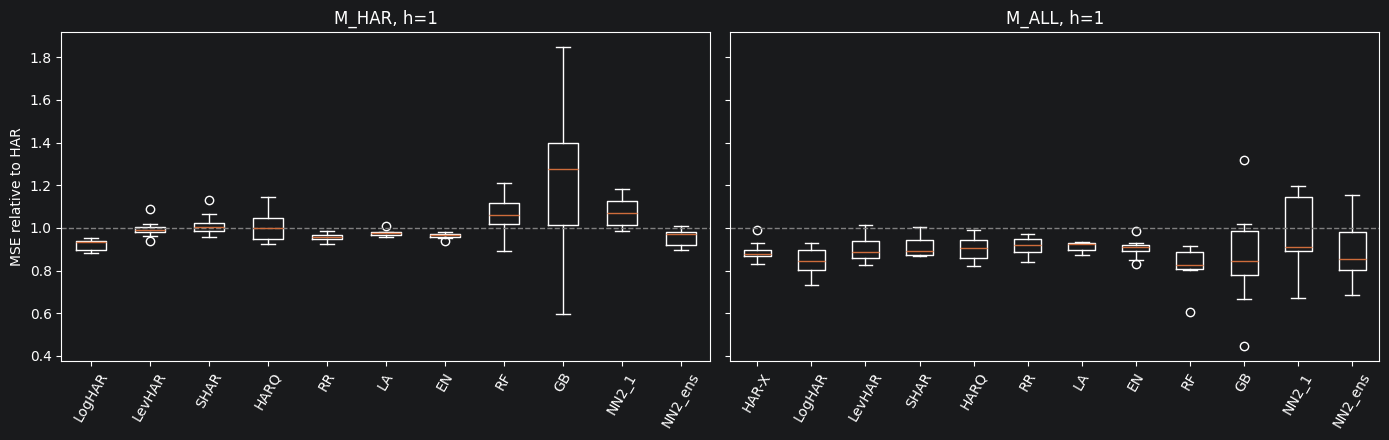

In [9]:
fig, axes = plt.subplots(1, 2, figsize=(14, 4.5), sharey=True)
for ax, ds in zip(axes, cfg.datasets):
    R = V.per_stock_relative(preds, ds, 1).drop(columns="HAR")
    ax.boxplot(R.values, tick_labels=R.columns)
    ax.axhline(1, color="grey", lw=1, ls="--"); ax.set_title(f"{ds}, h=1"); ax.tick_params(axis="x", rotation=60)
axes[0].set_ylabel("MSE relative to HAR")
plt.tight_layout(); plt.savefig(f"{cfg.results_dir}/fig3_boxplot.png", dpi=200); plt.show()

## 5. Accuracy across the volatility distribution (cf. paper Figure 5)

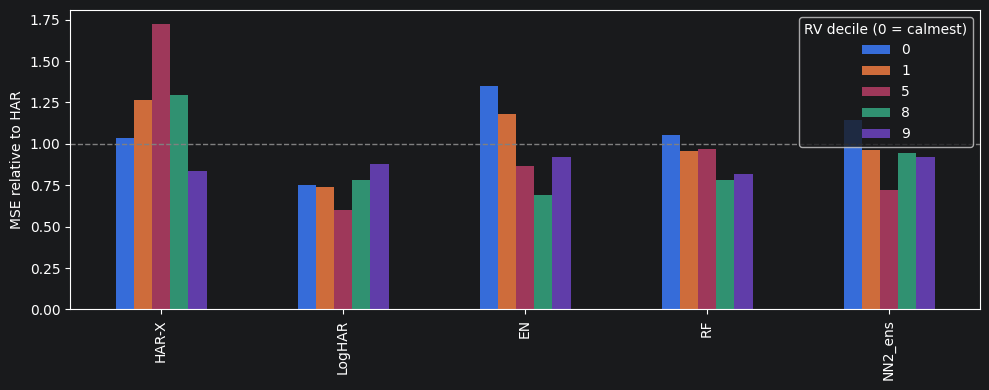

,HAR-X,LogHAR,EN,RF,NN2_ens
decile,,,,,
0,1.035,0.750,1.351,1.051,1.145
1,1.265,0.740,1.181,0.955,0.962
2,1.345,0.730,1.118,1.045,0.958
3,1.278,0.643,1.081,1.069,0.754
4,1.530,0.711,1.084,1.176,0.889
5,1.722,0.603,0.864,0.972,0.724
6,1.520,0.578,0.841,0.936,0.632
7,1.412,0.704,0.735,0.892,0.793
8,1.296,0.784,0.688,0.779,0.945


In [10]:
best_nn = [c for c in preds[s0][("M_ALL", 1)].columns if c.endswith("_ens")][0]
dec = V.decile_table(preds, "M_ALL", 1, models=["HAR-X", "LogHAR", "EN", "RF", best_nn])
ax = dec.loc[[0, 1, 5, 8, 9]].T.plot.bar(figsize=(10, 4)); ax.axhline(1, color="grey", ls="--", lw=1)
ax.set_ylabel("MSE relative to HAR"); ax.legend(title="RV decile (0 = calmest)")
plt.tight_layout(); plt.savefig(f"{cfg.results_dir}/fig5_deciles.png", dpi=200); plt.show()
dec.round(3)

## 6. Opening the black box: ALE and variable importance (cf. paper Figures 6–7)

Models are fitted on the initial training set ($\mathcal M_{ALL}$, h = 1); importance = standard deviation of the centered accumulated local effect, normalized to sum to one, averaged across stocks.

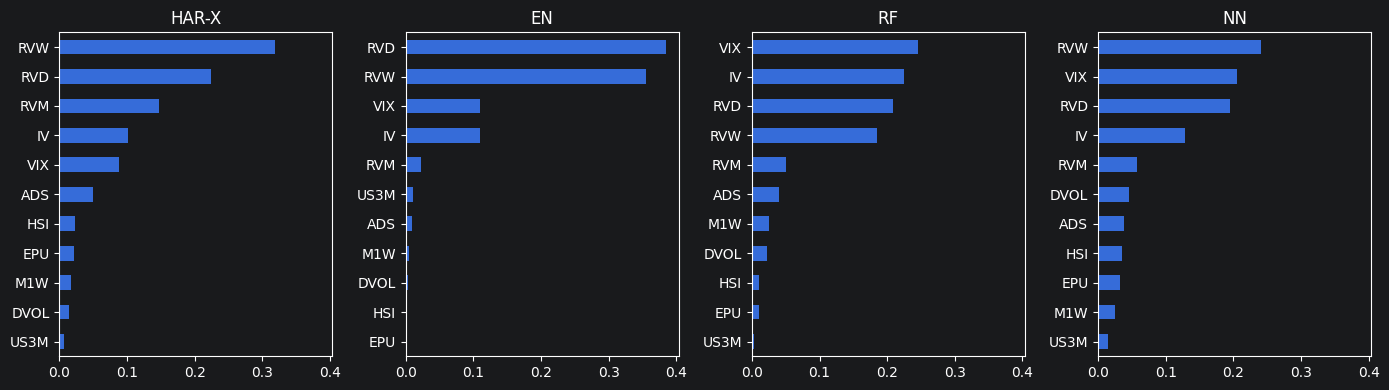

,HAR-X,EN,RF,NN
ADS,0.050,0.009,0.040,0.038
DVOL,0.014,0.004,0.023,0.046
EPU,0.021,0.000,0.011,0.032
HSI,0.023,0.001,0.011,0.035
IV,0.101,0.110,0.226,0.129
M1W,0.018,0.005,0.025,0.025
RVD,0.224,0.384,0.208,0.194
RVM,0.147,0.023,0.050,0.057
RVW,0.319,0.356,0.185,0.240
US3M,0.007,0.010,0.003,0.014


In [11]:
d_tr, d_va = V.split_dates(panel[panel.date >= cfg.start], cfg)
vi_syms = cfg.symbols[:8]                       # VI is the slowest part; 8 stocks are enough for the figure
vis, fitted_aapl = [], None
for s in vi_syms:
    vi, fitted, tr = V.vi_for_stock(panel[panel.symbol == s], macro, cfg, d_tr, d_va,
                                    ea=None if ea is None else ea[ea.symbol == s],
                                    iv=None if iv is None else iv[iv.symbol == s])
    vis.append(vi)
    if s == vi_syms[0]:
        fitted_aapl, tr_aapl = fitted, tr
VI = pd.concat(vis).groupby(level=0).mean()     # ignores stocks where a model is constant (NaN)
fig, axes = plt.subplots(1, VI.shape[1], figsize=(14, 4), sharex=True)
for ax, m in zip(axes, VI.columns):
    VI[m].sort_values().plot.barh(ax=ax); ax.set_title(m)
plt.tight_layout(); plt.savefig(f"{cfg.results_dir}/fig7_variable_importance.png", dpi=200); plt.show()
VI.round(3)

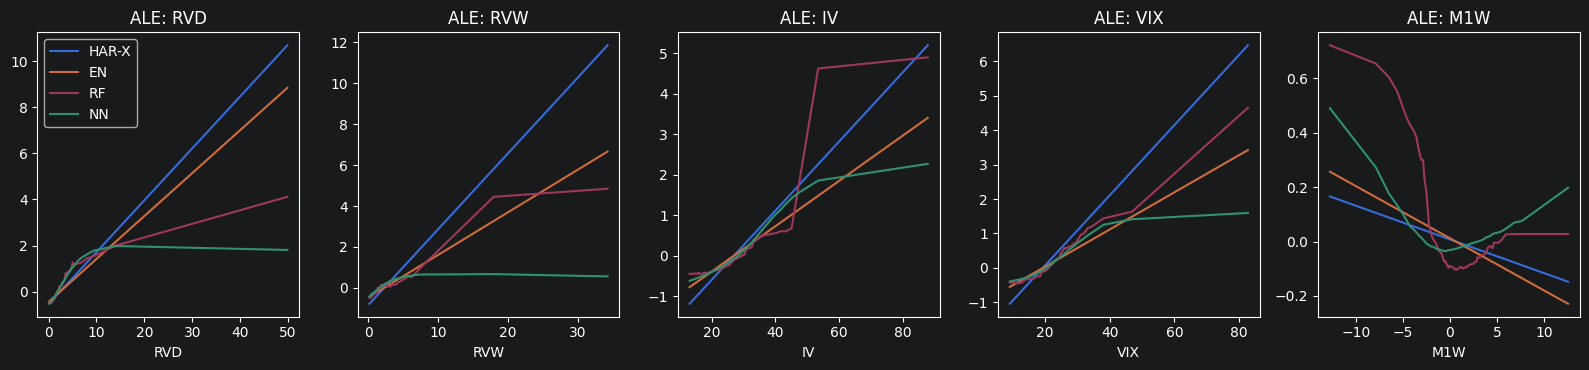

In [12]:
# ALE curves for the first stock (paper Figure 6 uses Apple)
cols = [c for c in ["RVD", "RVW", "IV", "VIX", "M1W"] if c in tr_aapl]
fig, axes = plt.subplots(1, len(cols), figsize=(16, 3.8))
for ax, c in zip(axes, cols):
    for name, m in fitted_aapl.items():
        e, a, _ = V.ale(m, tr_aapl, c)
        ax.plot(e, a, label=name)
    ax.set_title(f"ALE: {c}"); ax.set_xlabel(c)
axes[0].legend(); plt.tight_layout(); plt.savefig(f"{cfg.results_dir}/fig6_ale.png", dpi=200); plt.show()

## 7. Deviations from the original paper (state these on a slide)

| Paper | This replication | Why |
|---|---|---|
| NYSE TAQ, 29 DJIA stocks, 2001–2017 | VOLARE 5-min RV, Dow 30, 2015–latest | TAQ is not available to us; VOLARE is open and built from cleaned tick data with the same 5-min RV estimator |
| Model-free IV per stock (OptionMetrics) | 30-day ATM implied vol from LSEG Workspace (if `fetch_iv_lseg.py` was run), otherwise omitted; VIX keeps the market-implied-vol channel | OptionMetrics not available to us |
| Earnings announcement dummy | Omitted (optional CSV hook) | No clean open source for 2016–2026 |
| Tuning and RF/GB re-estimated daily | OLS daily; regularization every 22 days, trees every 63 days (configurable) | Compute budget on laptops; hyperparameters tuned once on the validation block |
| NN: L-ReLU, dropout, 100 seeds → best 10 | scikit-learn MLP, ReLU, L2 + early stopping, 10 seeds → best 5 | Paper reports ReLU makes no material difference (fn. 7) |
| Adaptive / post lasso, bagging, MCS, VaR | Not run by default (BG available via `cfg.models`) | Scope for one week |

Additional: QLIKE as a second loss function; explicit no-look-ahead rule for multi-day targets.